### Exercice 13 — Réduction de dimension avec PCA

In [98]:
import numpy as np

import pandas as pd

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.preprocessing import OneHotEncoder , OrdinalEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

from  sklearn.model_selection  import train_test_split

import matplotlib.pyplot as plt

### Creation du dataframe du ex1 avec deux nouvelle colonne

In [99]:
rng = np.random.default_rng(42)

n = 200

age = rng.normal(loc=35, scale=12, size=n)

age = np.clip(age, 18, 80).astype(int)

niveau_education = []

for a in age:

    if a < 25:
        choix = ["Collège", "Lycée", "Bac+2", "Bac+3", "Bac+5", "Doctorat"]

        proba = [0.05, 0.30, 0.30, 0.20, 0.12, 0.03]

    elif a < 35:
        choix = ["Lycée", "Bac+2", "Bac+3", "Bac+5", "Doctorat"]

        proba = [0.15, 0.25, 0.25, 0.28, 0.07]

    else:
        choix = ["Lycée", "Bac+2", "Bac+3", "Bac+5", "Doctorat"]

        proba = [0.20, 0.25, 0.20, 0.25, 0.10]

    niveau_education.append(

        rng.choice(choix, p=proba)

    )

ville = rng.choice(
    ["Paris", "Lyon", "Marseille", "Toulouse", "Nice", "Nantes"],
    size=n,
    p=[0.30, 0.15, 0.15, 0.15, 0.10, 0.15]
)

genre = rng.choice(
    ["Homme", "Femme", "Autre"],
    size=n,
    p=[0.48, 0.48, 0.04]
)

statut_marital = []

for a in age:

    if a < 25:
        choix = ["Célibataire", "Marié", "Divorcé", "Veuf"]
        proba = [0.85, 0.12, 0.03, 0.00]

    elif a < 35:
        choix = ["Célibataire", "Marié", "Divorcé", "Veuf"]
        proba = [0.45, 0.45, 0.09, 0.01]

    elif a < 50:
        choix = ["Célibataire", "Marié", "Divorcé", "Veuf"]
        proba = [0.25, 0.60, 0.13, 0.02]

    else:
        choix = ["Célibataire", "Marié", "Divorcé", "Veuf"]
        proba = [0.15, 0.60, 0.15, 0.10]

    statut_marital.append(
        rng.choice(choix, p=proba)
    )

taille_cm = rng.normal(
    loc=172,
    scale=9,
    size=n
)

taille_cm = np.clip(taille_cm, 150, 200).round(1)

effet_education = {
    "Collège": 0,
    "Lycée": 5000,
    "Bac+2": 10000,
    "Bac+3": 15000,
    "Bac+5": 25000,
    "Doctorat": 35000
}

effet_ville = {
    "Paris": 18000,
    "Lyon": 9000,
    "Marseille": 4000,
    "Toulouse": 6000,
    "Nice": 7000,
    "Nantes": 5000
}

salaire_annuel = (
    18000
    + age * 700
    + np.array([effet_education[x] for x in niveau_education])
    + np.array([effet_ville[x] for x in ville])
    + rng.normal(0, 10000, n)
)

salaire_annuel = np.clip(
    salaire_annuel,
    20000,
    150000
).round(0)

score_sante = (
    100
    - (age - 18) * 0.8
    + rng.normal(0, 5, n)
)

score_sante = np.clip(
    score_sante,
    0,
    100
).round(1)

anciennete_emploi_annees = (
    (age - 18) * 0.55
    + rng.normal(0, 2.5, n)
)

anciennete_emploi_annees = np.clip(
    anciennete_emploi_annees,
    0,
    40
).round(1)

df = pd.DataFrame({
    "age": age,
    "salaire_annuel": salaire_annuel,
    "taille_cm": taille_cm,
    "niveau_education": niveau_education,
    "ville": ville,
    "genre": genre,
    "statut_marital": statut_marital,
    "score_sante": score_sante,
    "anciennete_emploi_annees": anciennete_emploi_annees
})

df

,age,salaire_annuel,taille_cm,niveau_education,ville,genre,statut_marital,score_sante,anciennete_emploi_annees
0,38,35519.0,171.0,Lycée,Nantes,Autre,Célibataire,88.1,10.5
1,22,42231.0,174.0,Lycée,Nantes,Femme,Célibataire,98.8,3.1
2,44,61821.0,177.6,Lycée,Paris,Femme,Marié,71.2,14.3
3,46,81351.0,163.0,Bac+5,Nice,Homme,Célibataire,77.5,11.8
4,18,37598.0,162.6,Lycée,Paris,Femme,Célibataire,100.0,0.0
...,...,...,...,...,...,...,...,...,...
195,24,39530.0,194.1,Bac+2,Toulouse,Femme,Célibataire,89.4,0.3
196,42,74686.0,188.2,Bac+2,Marseille,Femme,Célibataire,81.6,15.3
197,30,83456.0,168.3,Bac+5,Nice,Homme,Marié,94.0,4.3
198,34,81396.0,168.7,Bac+5,Nantes,Femme,Célibataire,79.3,15.8


### Fonction de creation de la colonne "revenu_eleve"

In [100]:
mediane_salaire =  df["salaire_annuel"].median()

def calcul_revenu_eleve(salaire):

    if salaire > mediane_salaire : 

        return 1

    else :

        return 0

In [101]:
y = df["salaire_annuel"].apply(calcul_revenu_eleve)

In [102]:
df

,age,salaire_annuel,taille_cm,niveau_education,ville,genre,statut_marital,score_sante,anciennete_emploi_annees
0,38,35519.0,171.0,Lycée,Nantes,Autre,Célibataire,88.1,10.5
1,22,42231.0,174.0,Lycée,Nantes,Femme,Célibataire,98.8,3.1
2,44,61821.0,177.6,Lycée,Paris,Femme,Marié,71.2,14.3
3,46,81351.0,163.0,Bac+5,Nice,Homme,Célibataire,77.5,11.8
4,18,37598.0,162.6,Lycée,Paris,Femme,Célibataire,100.0,0.0
...,...,...,...,...,...,...,...,...,...
195,24,39530.0,194.1,Bac+2,Toulouse,Femme,Célibataire,89.4,0.3
196,42,74686.0,188.2,Bac+2,Marseille,Femme,Célibataire,81.6,15.3
197,30,83456.0,168.3,Bac+5,Nice,Homme,Marié,94.0,4.3
198,34,81396.0,168.7,Bac+5,Nantes,Femme,Célibataire,79.3,15.8


### Standardisation de colonne numerique

In [103]:
num_col = ["age", "salaire_annuel", "taille_cm", "score_sante", "anciennete_emploi_annees"]

stand =  StandardScaler()

df[num_col] = stand.fit_transform(df[num_col])

df


,age,salaire_annuel,taille_cm,niveau_education,ville,genre,statut_marital,score_sante,anciennete_emploi_annees
0,0.362327,-1.800245,-0.161035,Lycée,Nantes,Autre,Célibataire,0.172487,0.278492
1,-1.204494,-1.408668,0.193537,Lycée,Nantes,Femme,Célibataire,1.264240,-0.957396
2,0.949885,-0.265789,0.619024,Lycée,Paris,Femme,Marié,-1.551871,0.913138
3,1.145738,0.873590,-1.106561,Bac+5,Nice,Homme,Célibataire,-0.909063,0.495608
4,-1.596199,-1.678956,-1.153837,Lycée,Paris,Femme,Célibataire,1.386680,-1.475133
...,...,...,...,...,...,...,...,...,...
195,-1.008641,-1.566244,2.569171,Bac+2,Toulouse,Femme,Célibataire,0.305130,-1.425030
196,0.754033,0.484754,1.871846,Bac+2,Marseille,Femme,Célibataire,-0.490728,1.080150
197,-0.421083,0.996395,-0.480150,Bac+5,Nice,Homme,Marié,0.774482,-0.756982
198,-0.029378,0.876215,-0.432874,Bac+5,Nantes,Femme,Célibataire,-0.725404,1.163656


### Standardisation des autre colonne

In [104]:
encoder  =  OrdinalEncoder()

encoder.fit(df[["niveau_education"]])

df["niveau_education"] = encoder.transform(df[["niveau_education"]])

col = ["ville","genre","statut_marital"]

encoder_vgs = OneHotEncoder(sparse_output=False)

tab = encoder_vgs.fit_transform(df[col])

df_encode = pd.DataFrame(
    tab,
    columns=encoder_vgs.get_feature_names_out(col),
    index=df.index
)

df = df.drop(col,axis=1)

df = df.join(df_encode)

df


,age,salaire_annuel,taille_cm,niveau_education,score_sante,anciennete_emploi_annees,ville_Lyon,ville_Marseille,ville_Nantes,ville_Nice,ville_Paris,ville_Toulouse,genre_Autre,genre_Femme,genre_Homme,statut_marital_Célibataire,statut_marital_Divorcé,statut_marital_Marié,statut_marital_Veuf
0,0.362327,-1.800245,-0.161035,4.0,0.172487,0.278492,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.204494,-1.408668,0.193537,4.0,1.264240,-0.957396,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,0.949885,-0.265789,0.619024,4.0,-1.551871,0.913138,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1.145738,0.873590,-1.106561,2.0,-0.909063,0.495608,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
4,-1.596199,-1.678956,-1.153837,4.0,1.386680,-1.475133,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1.008641,-1.566244,2.569171,0.0,0.305130,-1.425030,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
196,0.754033,0.484754,1.871846,0.0,-0.490728,1.080150,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
197,-0.421083,0.996395,-0.480150,2.0,0.774482,-0.756982,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
198,-0.029378,0.876215,-0.432874,2.0,-0.725404,1.163656,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


### Application du la PCA

In [105]:
pca = PCA()

x_pca =  pca.fit_transform(df)

### Courbe de la variance expliqué cumulée

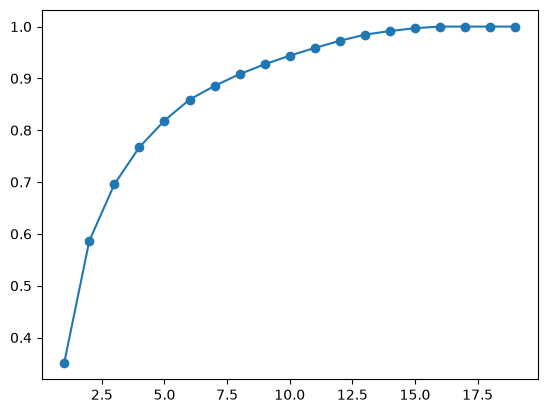

In [106]:
vc = np.cumsum(pca.explained_variance_ratio_)

fig , ax =  plt.subplots()

ax.plot(

    range(1, len(vc) +1 ),

    vc ,

    marker="o"

)

### Nombre de composant qui explique 90%  de la variance

In [127]:
pca =  PCA(n_components=0.9)

x_pca_fin =  pca.fit_transform(df)

pca.n_components_


np.int64(8)

### Projection des données dans un espace reduit a 2 composant

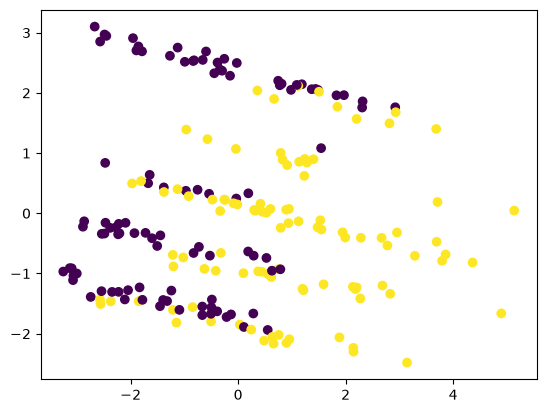

In [128]:
pca =  PCA(n_components=2)

x_pca =  pca.fit_transform(df)

fig , ax =  plt.subplots()

ax.scatter(

    x_pca[:,0],

    x_pca[:,1],

    c= y
)


### Entrainement d'un model de Regression logistique

### Model 1

Separation du train et du test 

In [129]:
x_train_m1 , x_test_m1 , y_train , y_test = train_test_split(df, y , test_size=0.3)

In [135]:
model1 =  LogisticRegression()

model1.fit(x_train_m1 , y_train)

pred_m1 =  model1.predict(x_test_m1)

model1.score(x_train_m1 , y_train)

0.6642857142857143

### Model 2

Separation du train et du test

In [136]:
x_train_m2 , x_test_m2 , y_train , y_test = train_test_split(x_pca_fin, y , test_size=0.3)

In [137]:
model2 =  LogisticRegression()

model2.fit(x_train_m2 , y_train)

pred_m2 =  model2.predict(x_test_m2)

model2.score(x_train_m2 , y_train)

0.9642857142857143

### Comparaison des accuracy score

Model 1

In [138]:
accuracy_score(y_test,pred_m1)

0.4

Model 2

In [139]:
accuracy_score(y_test,pred_m2)

1.0